In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import urlsplit

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

def load(name):
    return pd.read_csv(f"../data/raw/{name}.csv", dtype=str, keep_default_na=False)

sessions, events, pages, campaigns = load("sessions"), load("events"), load("pages"), load("campaigns")
for name, df in [("sessions", sessions), ("events", events), ("pages", pages), ("campaigns", campaigns)]:
    print(f"{name:10s} {df.shape[0]:>6} rows  {df.shape[1]} columns")

sessions    20778 rows  9 columns
events      45498 rows  6 columns
pages          11 rows  4 columns
campaigns       3 rows  8 columns


The dictionary says `session_id` and `event_id` should be unique. This section compares the number of rows with the number of unique IDs.

In [2]:
print("sessions: rows", len(sessions), "| unique session_id", sessions["session_id"].nunique(),
      "| exact duplicate rows", sessions.duplicated().sum())
print("events:   rows", len(events), "| unique event_id", events["event_id"].nunique(),
      "| exact duplicate rows", events.duplicated().sum())
print("\nrepeated session_id after removing exact copies:", sessions.drop_duplicates()["session_id"].duplicated().sum())
print("repeated event_id after removing exact copies:  ", events.drop_duplicates()["event_id"].duplicated().sum())

sessions: rows 20778 | unique session_id 20748 | exact duplicate rows 30
events:   rows 45498 | unique event_id 45378 | exact duplicate rows 120

repeated session_id after removing exact copies: 0
repeated event_id after removing exact copies:   0


30 duplicate sessions and 120 duplicate events were found. After removing them every ID is unique, so there are no conflicting versions of the same row.

This section looks for blank values

In [3]:
blanks = pd.DataFrame({
    "sessions": (sessions == "").sum(),
    "events": (events == "").sum(),
})
blanks[(blanks.sessions > 0) | (blanks.events > 0)].fillna(0).astype(int)

,sessions,events
campaign_id,18051,0
country_code,90,0
medium,45,0
source,45,0


`country_code` is blank in 90 sessions (the dictionary says blank = unknown). `source` and `medium` are blank in 45 sessions. `campaign_id` is blank in about 18,000 sessions, which is expected because most sessions have no campaign.

This section looks for unexpected values

In [4]:
for col in ["device_category", "medium", "country_code", "source"]:
    print(sessions[col].map(repr).value_counts().to_string(), "\n")
print(events["event_name"].value_counts().to_string())

device_category
'mobile'       10487
'desktop'       9505
'tablet'         726
'Mobile'          32
' DESKTOP '       24
'Tablet'           4 

medium
'organic'     6188
'social'      4800
'(none)'      4303
'referral'    3304
'email'       2138
''              45 

country_code
'GB'    15297
'US'     1673
'IE'     1144
'IN'      776
'SG'      624
'DE'      484
'FR'      408
'NL'      282
''         90 

source
'google'                          5556
'(direct)'                        4303
'linkedin'                        3831
'university.example'              2031
'placement-newsletter.example'    1548
'traffic-check.example'           1353
'instagram'                        969
'bing'                             632
'careers-fair.example'             510
''                                  45 

event_name
page_view                  38822
apply_cta_click             3214
video_play                  1969
application_email_click     1493


Device labels are inconsistent (`Mobile`, ` DESKTOP` with a leading space, `Tablet`): 60 values. One source, `traffic-check.example`, looks unusual and is investigated in section 8. All four event names are the documented ones.

This section looks for invalid timestamps

In [5]:
s_ts = pd.to_datetime(sessions["session_start_utc"], errors="coerce", utc=True)
e_ts = pd.to_datetime(events["event_timestamp_utc"], errors="coerce", utc=True)
print("sessions: unparseable timestamps", s_ts.isna().sum(), "| range", s_ts.min(), "to", s_ts.max())
print("events:   unparseable timestamps", e_ts.isna().sum(), "| range", e_ts.min(), "to", e_ts.max())
print("\nbad event timestamp values:", events.loc[e_ts.isna(), "event_timestamp_utc"].unique())
print("event types with a bad timestamp:", events.loc[e_ts.isna(), "event_name"].value_counts().to_dict())

sessions: unparseable timestamps 0 | range 2025-09-01 07:03:23+00:00 to 2026-02-28 22:07:12+00:00
events:   unparseable timestamps 8 | range 2025-09-01 07:03:23+00:00 to 2026-02-28 22:08:02+00:00

bad event timestamp values: <StringArray>
['not-a-timestamp']
Length: 1, dtype: str
event types with a bad timestamp: {'page_view': 8}


All session timestamps are valid and inside the stated date range. 8 events have the text `not-a-timestamp` and all are page views.

This section looks for invalid engagment time

In [6]:
eng = pd.to_numeric(events["engagement_seconds"])
print(eng.describe().round(1).to_string())
print("\nnegative values:", (eng < 0).sum(), "| event types:", events.loc[eng < 0, "event_name"].value_counts().to_dict())

count    45498.0
mean        30.3
std         29.1
min         -5.0
25%          0.0
50%         26.0
75%         48.0
max        182.0

negative values: 10 | event types: {'page_view': 10}


10 page views have negative engagement seconds, which is impossible.

The same page can appear as several different URLs. Strip the query string, fragment and trailing slash, then check against the page catalogue. (According to the Dictionary)

In [7]:
def clean_path(url):
    path = urlsplit(url).path or "/"
    return path if path == "/" else path.rstrip("/")

for name, df, col in [("session landing URLs", sessions, "landing_page_url"), ("event page URLs", events, "page_url")]:
    url = df[col]
    print(f"{name}: {len(url)} URLs, {url.nunique()} distinct raw strings")
    print("   with ? or #:", url.str.contains(r"[?#]").sum(), "| trailing slash:", url.str.contains(r"[^/]/$").sum())
    paths = url.map(clean_path)
    print("   distinct clean paths:", paths.nunique(), "| not in pages.csv:", (~paths.isin(pages["page_path"])).sum(), "\n")

query_names = events["page_url"].map(lambda u: urlsplit(u).query).loc[lambda s: s != ""].str.split("&").explode().str.split("=").str[0]
print("query parameters seen:", query_names.value_counts().to_dict())

session landing URLs: 20778 URLs, 98 distinct raw strings
   with ? or #: 3511 | trailing slash: 9163
   distinct clean paths: 11 | not in pages.csv: 0 

event page URLs: 45498 URLs, 98 distinct raw strings
   with ? or #: 6169 | trailing slash: 12871
   distinct clean paths: 11 | not in pages.csv: 0 

query parameters seen: {'ref': 3541, 'utm_campaign': 1765, 'utm_source': 1765}


After cleaning, everything maps to the 11 pages in `pages.csv`. There are 4 role pages (Data Engineer, Software Engineer, Technical Analyst, Marketing Associate)

This section checks whether the files connect to each other properly (referential integrity)

In [8]:
orph = ~events["session_id"].isin(sessions["session_id"])
print("events whose session_id is not in sessions:", orph.sum(), events.loc[orph, "event_name"].value_counts().to_dict())
print("sessions with no events at all:", (~sessions["session_id"].isin(events["session_id"])).sum())
s = sessions.drop_duplicates().copy()
s["date"] = s["session_start_utc"].str[:10]
camp = s[s["campaign_id"] != ""].merge(campaigns, on="campaign_id", how="left", suffixes=("", "_c"))
print("\nsessions with a campaign_id that is not in campaigns.csv:", camp["campaign_name"].isna().sum())
print("campaign sessions dated outside the campaign window:", ((camp["date"] < camp["start_date"]) | (camp["date"] > camp["end_date"])).sum())
print("campaign sessions with blank source/medium:", ((camp["source"] == "") | (camp["medium"] == "")).sum())

events whose session_id is not in sessions: 12 {'page_view': 12}
sessions with no events at all: 0

sessions with a campaign_id that is not in campaigns.csv: 0
campaign sessions dated outside the campaign window: 0
campaign sessions with blank source/medium: 9


12 events point to sessions that do not exist (orphans, all page views). Every session has events. All campaign IDs exist and all campaign sessions fall inside their windows. 9 campaign sessions have blank source/medium, so they should be flagged as`Unknown`, not dropped.

This section checks for "Unusual Traffic"

In [9]:
s["ts"] = pd.to_datetime(s["session_start_utc"], utc=True)
t = s[s["source"] == "traffic-check.example"]
ev_t = events[events["session_id"].isin(t["session_id"])]
print("sessions:", len(t), "| unique visitors:", t["visitor_id"].nunique())
print("dates:", t["date"].value_counts().sort_index().to_dict())
print("device:", t["device_category"].str.strip().str.lower().value_counts().to_dict(), "| country:", t["country_code"].value_counts().to_dict())
print("landing paths:", t["landing_page_url"].map(clean_path).value_counts().to_dict())
print("events per session:", round(len(ev_t) / len(t), 2), "(all other sessions:", round((len(events) - len(ev_t)) / (len(s) - len(t)), 2), ")")
print("event types:", ev_t["event_name"].value_counts().to_dict())

sessions: 1350 | unique visitors: 1350
dates: {'2026-01-14': 450, '2026-01-15': 450, '2026-01-16': 450}
device: {'desktop': 1350} | country: {'US': 930, 'SG': 420}
landing paths: {'/': 1350}
events per session: 1.0 (all other sessions: 2.28 )
event types: {'page_view': 1354}


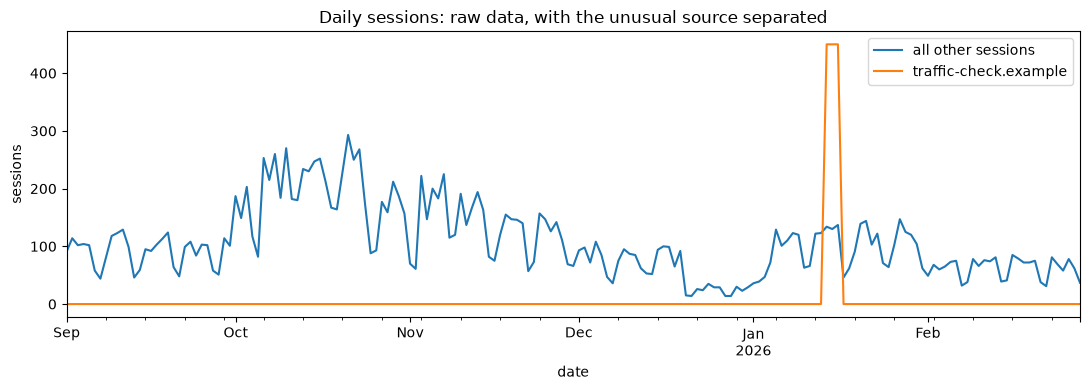

In [10]:
daily = s.groupby(["date", s["source"] == "traffic-check.example"]).size().unstack(fill_value=0)
daily.columns = ["all other sessions", "traffic-check.example"]
daily.index = pd.to_datetime(daily.index)
ax = daily.plot(figsize=(11, 4), title="Daily sessions: raw data, with the unusual source separated")
ax.set_ylabel("sessions"); plt.tight_layout(); plt.show()

Exactly 450 sessions per day on 14, 15 and 16 January 2026, all desktop, all from US or Singapore, all landing on the home page, each with exactly one page view, no clicks, and a different visitor ID each time. These factors suggest that all this traffic was not produced by real users. This is most likely automated or test traffic, so it will be flagged and excluded from the main metrics, but not deleted.

## Summary of data-quality concerns and what can potentially be done

| # | Concern | Count | Decision (in `src/clean.py`) |
|---|---|---|---|
| 1 | Exact duplicate sessions | 30 | Remove |
| 2 | Exact duplicate events | 120 | Remove |
| 3 | Orphan events (no matching session) | 12 | Remove (cannot attribute to channel/device) |
| 4 | Inconsistent device labels | 60 | Trim and lower-case |
| 5 | Blank source and medium | 45 | Label `Unknown`, keep |
| 6 | Blank country | 90 | Label `Unknown`, keep |
| 7 | Invalid event timestamps | 8 | Keep the event, blank the timestamp, flag it |
| 8 | Negative engagement seconds | 10 | Keep the page view, blank the value |
| 9 | URL variations (query, fragment, slash) | thousands | Normalise to canonical path, keep original URL |
| 10 | Suspected automated traffic | 1,350 | Flag, exclude from rates, do not delete |
| 11 | No Data Analyst role page in the catalogue | n/a | State assumption in the analysis |
